In [1]:
import os
import shutil
import random
import re
import yaml
from collections import Counter, defaultdict
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from PIL import Image


In [2]:
raw = "data/photos/raw"
IMG = (".jpg", ".jpeg", ".png")

# 1) roboflow_quality: photos per class per split
print("== roboflow_quality ==")
for split in ["train", "valid", "test"]:
    p = f"{raw}/roboflow_quality/{split}"
    if os.path.isdir(p):
        print(split, {c: len([f for f in os.listdir(f"{p}/{c}") if f.lower().endswith(IMG)])
                      for c in sorted(os.listdir(p)) if os.path.isdir(f"{p}/{c}")})

# 2) roboflow_turbidity: class names + how many label boxes per class
print("\n== roboflow_turbidity ==")
print(open(f"{raw}/roboflow_turbidity/data.yaml").read())
cnt = Counter()
for split in ["train", "valid", "test"]:
    ld = f"{raw}/roboflow_turbidity/{split}/labels"
    if os.path.isdir(ld):
        for f in os.listdir(ld):
            for line in open(f"{ld}/{f}"):
                if line.strip():
                    cnt[line.split()[0]] += 1
print("boxes per class id:", dict(cnt))

# 3) mendeley
print("\n== mendeley_polluted ==")
for sub in ["clean", "images", "masks"]:
    p = f"{raw}/mendeley_polluted/{sub}"
    print(sub, len([f for f in os.listdir(p) if f.lower().endswith(IMG)]))

== roboflow_quality ==
train {'Clear': 25, 'Foam': 354, 'Highly_Turbid': 90, 'Medium_Turbid': 148, 'Unlabeled': 8}
valid {'Clear': 4, 'Foam': 88, 'Highly_Turbid': 27, 'Medium_Turbid': 40, 'Unlabeled': 2}
test {'Clear': 1, 'Foam': 263, 'Highly_Turbid': 17, 'Medium_Turbid': 96, 'Unlabeled': 1}

== roboflow_turbidity ==
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['clean', 'turbid']

roboflow:
  workspace: dataregenerator
  project: turbidity
  version: 4
  license: CC BY 4.0
  url: https://universe.roboflow.com/dataregenerator/turbidity/dataset/4


boxes per class id: {'1': 2194, '0': 374}

== mendeley_polluted ==
clean 300
images 1236
masks 1236


In [3]:
RAW = "data/photos/raw"
OUT = "data/photos/merged"
IMG = (".jpg", ".jpeg", ".png")
random.seed(42)

if os.path.exists(OUT):
    shutil.rmtree(OUT)

def put(src, split, cls, prefix):
    d = f"{OUT}/{split}/{cls}"
    os.makedirs(d, exist_ok=True)
    shutil.copy(src, f"{d}/{prefix}_{os.path.basename(src)}")

# 1) roboflow_quality: keep its own train/valid/test splits
q_map = {"Clear": "Clean", "Medium_Turbid": "Cloudy",
         "Highly_Turbid": "Cloudy", "Foam": "Foam"}
for s_in, s_out in [("train", "train"), ("valid", "valid"), ("test", "test")]:
    for folder, cls in q_map.items():
        d = f"{RAW}/roboflow_quality/{s_in}/{folder}"
        if os.path.isdir(d):
            for f in os.listdir(d):
                if f.lower().endswith(IMG):
                    put(f"{d}/{f}", s_out, cls, "rfq")

# 2) roboflow_turbidity: class = most common box label in the photo
names = yaml.safe_load(open(f"{RAW}/roboflow_turbidity/data.yaml"))["names"]
t_map = {"clean": "Clean", "turbid": "Cloudy"}
for s_in, s_out in [("train", "train"), ("valid", "valid"), ("test", "test")]:
    img_dir = f"{RAW}/roboflow_turbidity/{s_in}/images"
    lbl_dir = f"{RAW}/roboflow_turbidity/{s_in}/labels"
    if not os.path.isdir(img_dir):
        continue
    for f in os.listdir(img_dir):
        lbl = f"{lbl_dir}/{os.path.splitext(f)[0]}.txt"
        if not os.path.exists(lbl):
            continue
        ids = [l.split()[0] for l in open(lbl) if l.strip()]
        if not ids:
            continue
        cls = t_map[names[int(Counter(ids).most_common(1)[0][0])]]
        put(f"{img_dir}/{f}", s_out, cls, "rft")

# 3) mendeley: 70:15:15 - clean = split by file, polluted = split by original photo
def split_of(i, n):
    return "train" if i < int(n * 0.70) else ("valid" if i < int(n * 0.85) else "test")

M = f"{RAW}/mendeley_polluted"
clean = sorted(f for f in os.listdir(f"{M}/clean") if f.lower().endswith(IMG))
random.shuffle(clean)
for i, f in enumerate(clean):
    put(f"{M}/clean/{f}", split_of(i, len(clean)), "Clean", "mdl")

groups = defaultdict(list)
for f in os.listdir(f"{M}/images"):
    if f.lower().endswith(IMG):
        groups[re.sub(r"_aug\d+", "", os.path.splitext(f)[0])].append(f)
keys = sorted(groups)
random.shuffle(keys)
for i, k in enumerate(keys):
    for f in groups[k]:
        put(f"{M}/images/{f}", split_of(i, len(keys)), "Polluted", "mdl")

# result
for split in ["train", "valid", "test"]:
    print(split, {c: len(os.listdir(f"{OUT}/{split}/{c}"))
                  for c in sorted(os.listdir(f"{OUT}/{split}"))})

train {'Clean': 563, 'Cloudy': 2124, 'Foam': 354, 'Polluted': 864}
valid {'Clean': 78, 'Cloudy': 268, 'Foam': 88, 'Polluted': 186}
test {'Clean': 63, 'Cloudy': 217, 'Foam': 263, 'Polluted': 186}


(3276, 10)
ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object
                  count          mean          std         min           25%  \
ph               2785.0      7.080795     1.594320    0.000000      6.093092   
Hardness         3276.0    196.369496    32.879761   47.432000    176.850538   
Solids           3276.0  22014.092526  8768.570828  320.942611  15666.690297   
Chloramines      3276.0      7.122277     1.583085    0.352000      6.127421   
Sulfate          2495.0    333.775777    41.416840  129.000000    307.699498   
Conductivity     3276.0    426.205111    80.824064  181.483754    365.734414   
Organic_carbon   3276.0     14.284970     3.308162    2.200000     12.065801   
Trihalomethanes  3114.0     66.396293    16.175008    0.738000   

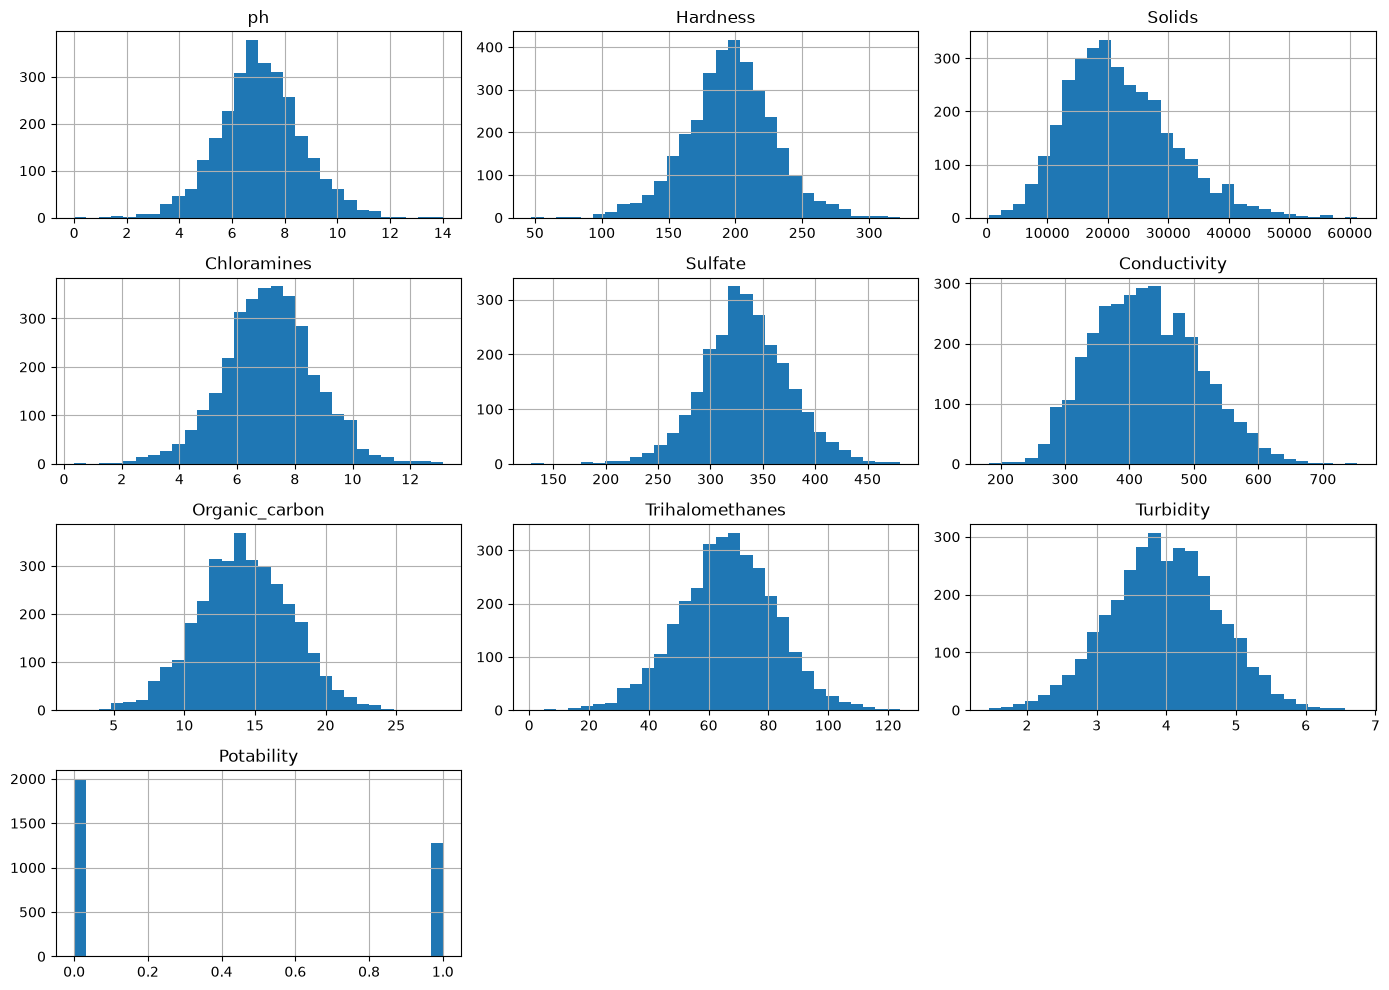

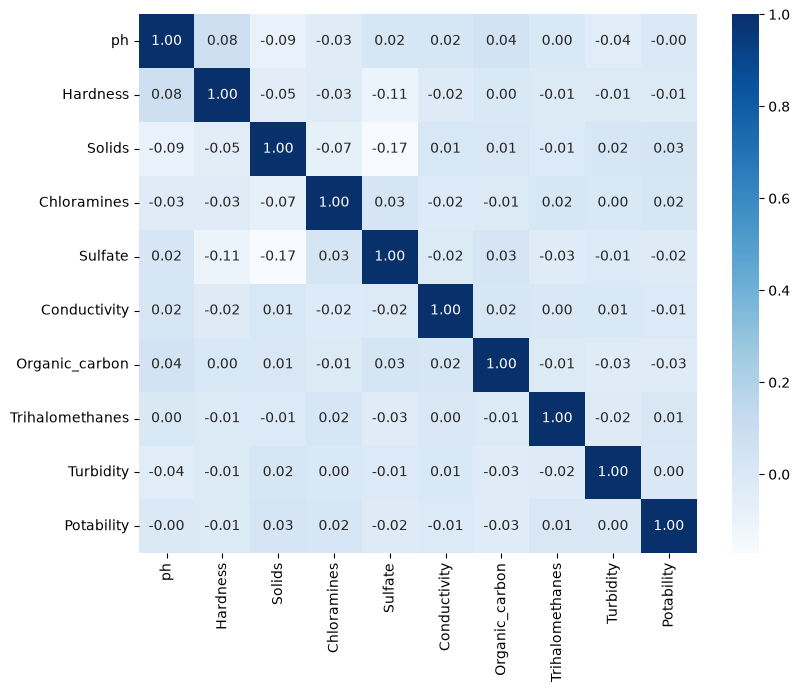

In [4]:
df = pd.read_csv("data/potability/water_potability.csv")

print(df.shape)
print(df.dtypes)
print(df.describe().T)
print("\nMissing values:\n", df.isna().sum())


df.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="Blues")
plt.show()

In [5]:
print(df["Potability"].value_counts())
print(df["Potability"].value_counts(normalize=True).round(3))

train_df, valid_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["Potability"]
)

medians = train_df.median()          # medians from TRAIN only
train_df = train_df.fillna(medians)
valid_df = valid_df.fillna(medians)

print("Missing after fill:", train_df.isna().sum().sum(), valid_df.isna().sum().sum())

train_df.to_csv("data/potability/train_clean.csv", index=False)
valid_df.to_csv("data/potability/valid_clean.csv", index=False)
medians.to_csv("data/potability/train_medians.csv")   # backend will need these

Potability
0    1998
1    1278
Name: count, dtype: int64
Potability
0    0.61
1    0.39
Name: proportion, dtype: float64
Missing after fill: 0 0


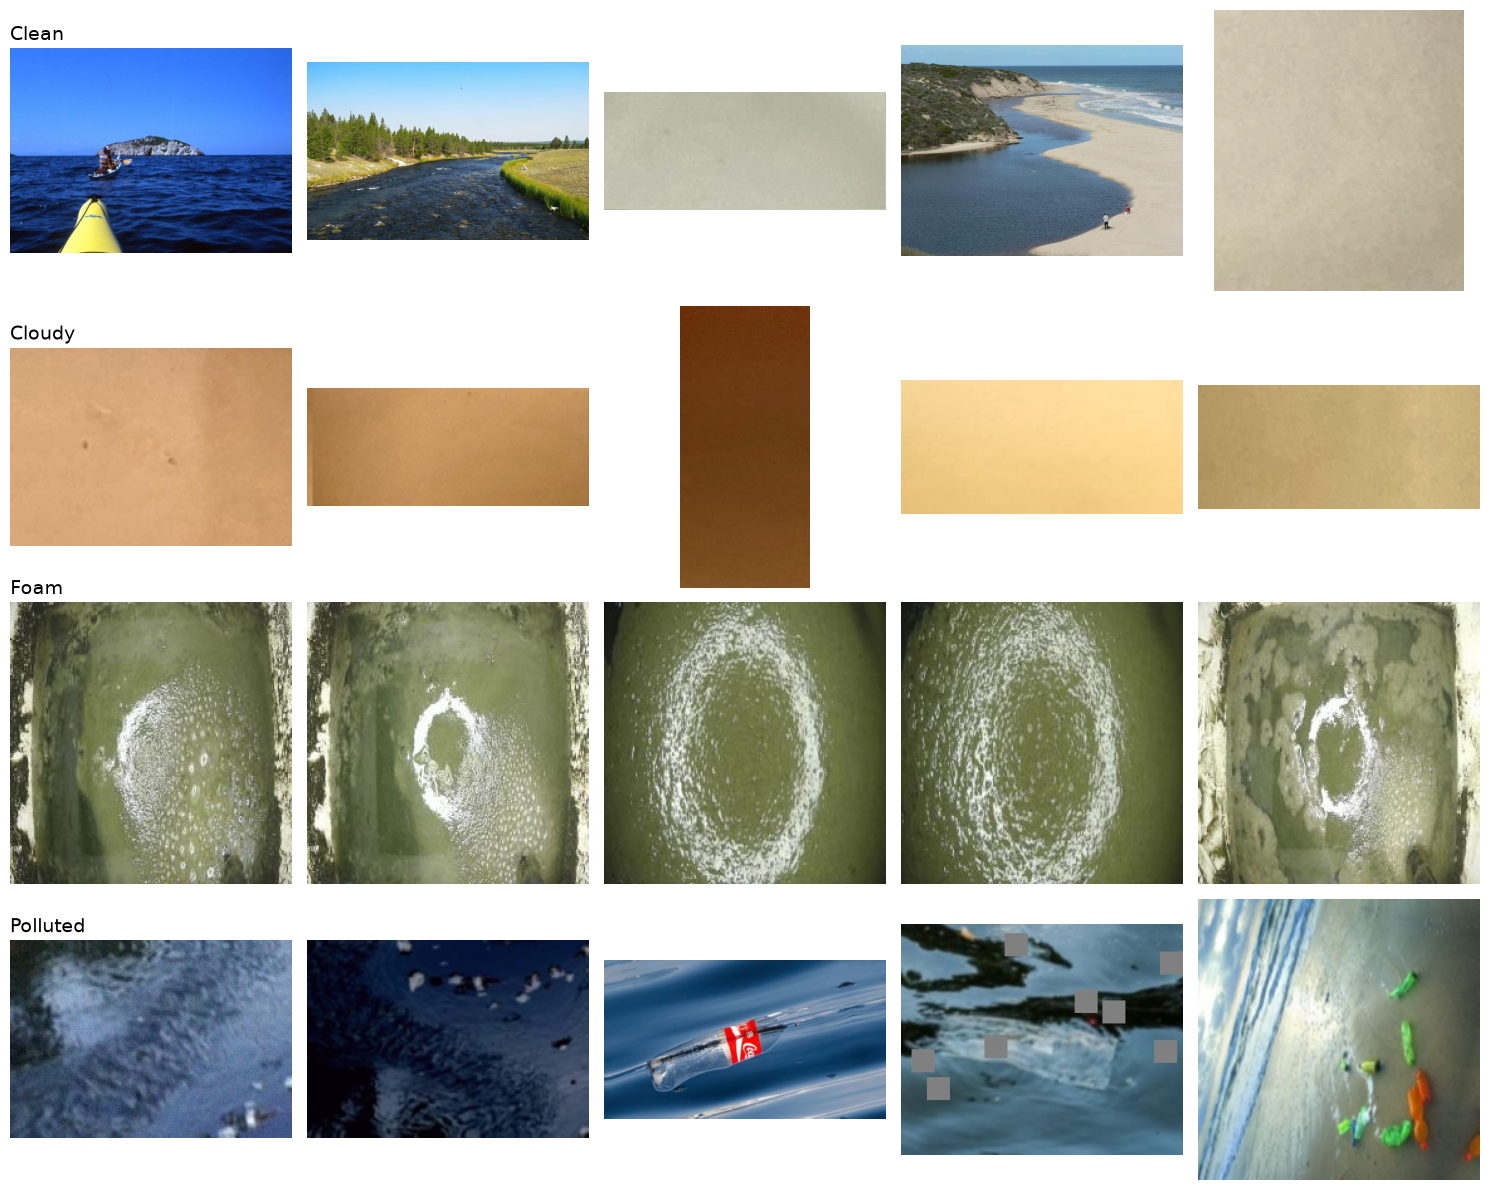

(224, 224)      25
(416, 416)       3
(1400, 933)      1
(216, 324)       1
(3456, 4608)     1
Name: count, dtype: int64


In [6]:
root = "data/photos/merged/train"
classes = sorted(os.listdir(root))
random.seed(1)

fig, axes = plt.subplots(len(classes), 5, figsize=(15, 3 * len(classes)))
for r, c in enumerate(classes):
    files = random.sample(os.listdir(f"{root}/{c}"), 5)
    for k, f in enumerate(files):
        axes[r, k].imshow(Image.open(f"{root}/{c}/{f}").convert("RGB"))
        axes[r, k].axis("off")
        if k == 0:
            axes[r, k].set_title(c, loc="left", fontsize=14)
plt.tight_layout()
plt.show()

# photo sizes
sizes = [Image.open(f"{root}/{c}/{f}").size
         for c in classes for f in random.sample(os.listdir(f"{root}/{c}"), 20)]
print(pd.Series(sizes).value_counts().head())

## Model 1 - Klasifikasi kondisi visual air dari foto
Transfer learning MobileNetV2 (bobot ImageNet, backbone dibekukan) + classifier dengan
pembobotan kelas. Model dipilih dengan data **valid**; angka akhir dilaporkan pada data **test**.

In [7]:
import json, time
import numpy as np
import torch, torch.nn as nn
from torchvision import datasets, models, transforms
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

torch.manual_seed(42); np.random.seed(42)
RES = "results"; os.makedirs(RES, exist_ok=True)
MERGED = "data/photos/merged"

tf_eval = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
tf_aug = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10), transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

backbone = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
backbone.classifier = nn.Identity()          # output: 1280-d embedding
backbone.eval()

@torch.no_grad()
def embed(split, tf):
    ds = datasets.ImageFolder(f"{MERGED}/{split}", transform=tf)
    dl = torch.utils.data.DataLoader(ds, batch_size=64, num_workers=0)
    X = torch.cat([backbone(x) for x, _ in dl]).numpy()
    return X, np.array(ds.targets), ds.classes

t0 = time.time()
Xtr, ytr, CLASSES = embed("train", tf_aug)   # augmentasi hanya pada data latih
Xva, yva, _ = embed("valid", tf_eval)
Xte, yte, _ = embed("test", tf_eval)
print("classes:", CLASSES, "| train/valid/test:", len(ytr), len(yva), len(yte),
      f"| {time.time()-t0:.0f}s")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\HP/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


  0%|          | 0.00/13.6M [00:00<?, ?B/s]

  1%|          | 128k/13.6M [00:00<00:14, 976kB/s]

  3%|▎         | 384k/13.6M [00:00<00:08, 1.62MB/s]

  6%|▌         | 768k/13.6M [00:00<00:05, 2.32MB/s]

  8%|▊         | 1.12M/13.6M [00:00<00:05, 2.43MB/s]

... (13 outputs left out)

 93%|█████████▎| 12.6M/13.6M [00:02<00:00, 9.01MB/s]

100%|██████████| 13.6M/13.6M [00:02<00:00, 9.09MB/s]

100%|██████████| 13.6M/13.6M [00:02<00:00, 6.67MB/s]

classes: ['Clean', 'Cloudy', 'Foam', 'Polluted'] | train/valid/test: 3905 620 729 | 344s


C=0.01: valid macro-F1=0.954


C=0.1: valid macro-F1=0.963


C=1.0: valid macro-F1=0.963
              precision    recall  f1-score   support

       Clean      0.612     1.000     0.759        63
      Cloudy      0.569     0.816     0.670       217
        Foam      0.985     0.490     0.655       263
    Polluted      0.995     0.984     0.989       186

    accuracy                          0.757       729
   macro avg      0.790     0.823     0.768       729
weighted avg      0.831     0.757     0.754       729



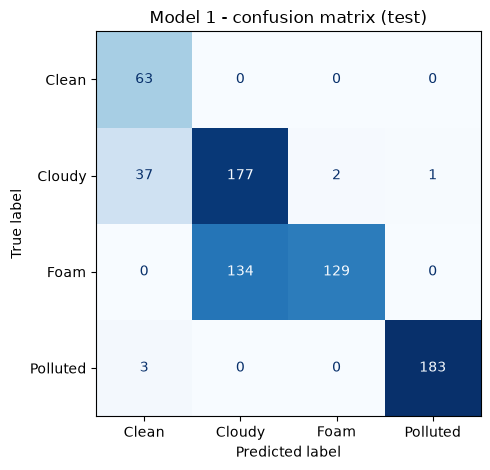

['../model/model1_head.joblib']

In [8]:
# classifier di atas embedding: pilih C terbaik berdasarkan macro-F1 di data valid
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

best = None
for C in [0.01, 0.1, 1.0]:
    clf = make_pipeline(StandardScaler(),
                        LogisticRegression(C=C, max_iter=3000, class_weight="balanced"))
    clf.fit(Xtr, ytr)
    f1v = f1_score(yva, clf.predict(Xva), average="macro")
    print(f"C={C}: valid macro-F1={f1v:.3f}")
    if best is None or f1v > best[0]:
        best = (f1v, C, clf)
f1_valid, C_best, m1 = best

pred = m1.predict(Xte)
m1_metrics = {
    "C": C_best, "valid_macro_f1": round(f1_valid, 4),
    "test_accuracy": round(accuracy_score(yte, pred), 4),
    "test_macro_precision": round(precision_score(yte, pred, average="macro"), 4),
    "test_macro_recall": round(recall_score(yte, pred, average="macro"), 4),
    "test_macro_f1": round(f1_score(yte, pred, average="macro"), 4),
    "per_class": classification_report(yte, pred, target_names=CLASSES, output_dict=True),
    "confusion": confusion_matrix(yte, pred).tolist(), "classes": CLASSES,
    "n": {"train": int(len(ytr)), "valid": int(len(yva)), "test": int(len(yte))}}
print(classification_report(yte, pred, target_names=CLASSES, digits=3))

ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=CLASSES).plot(cmap="Blues", colorbar=False)
plt.title("Model 1 - confusion matrix (test)"); plt.tight_layout()
plt.savefig(f"{RES}/model1_confusion.png", dpi=200); plt.show()
json.dump(m1_metrics, open(f"{RES}/model1_metrics.json", "w"), indent=2)

import joblib
os.makedirs("../model", exist_ok=True)
joblib.dump({"clf": m1, "classes": CLASSES}, "../model/model1_head.joblib")

## Model 2 - Prediksi risiko (Potability) dari kekeruhan, pH, TDS
Sesuai proposal hanya 3 fitur: `ph`, `Solids` (TDS), `Turbidity`. Algoritma dipilih dengan
5-fold stratified cross-validation pada data latih, lalu dievaluasi sekali pada data uji (20%).

{'solids_min': 320.942611274359, 'solids_median': 20866.335842223954, 'pct_solids_lt_300': 0.0, 'turb_min': 1.4922066153042484, 'turb_max': 6.739, 'pct_turb_lt_3': 10.839694656488549, 'pct_ph_in_range': 55.68702290076336}


                        model  cv_accuracy  cv_acc_sd  cv_f1_macro  cv_f1_sd
0  Baseline (kelas mayoritas)       0.6099     0.0009       0.3789    0.0004
1         Logistic Regression       0.5134     0.0246       0.5016    0.0233
2               Random Forest       0.5374     0.0194       0.5200    0.0194
3           Gradient Boosting       0.6019     0.0112       0.4574    0.0142


Random Forest
              precision    recall  f1-score   support

           0      0.639     0.593     0.615       400
           1      0.428     0.477     0.451       256

    accuracy                          0.547       656
   macro avg      0.533     0.535     0.533       656
weighted avg      0.557     0.547     0.551       656



RF 9 fitur: {'test_accuracy': 0.6509, 'test_macro_f1': 0.6221}


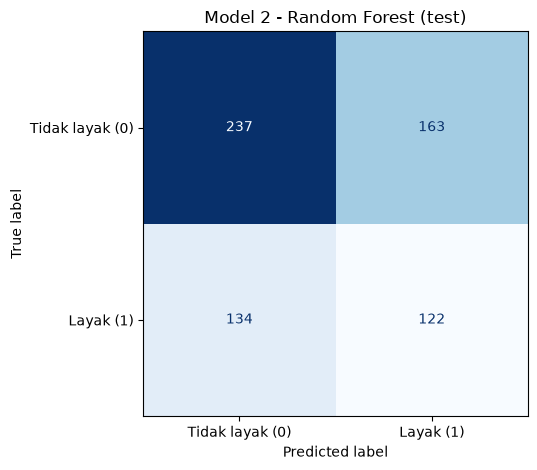

In [9]:
import json
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier

RES = "results"; os.makedirs(RES, exist_ok=True)
FEATS = ["ph", "Solids", "Turbidity"]
tr = pd.read_csv("data/potability/train_clean.csv")
te = pd.read_csv("data/potability/valid_clean.csv")   # 20% hold-out = data uji
Xtr2, ytr2, Xte2, yte2 = tr[FEATS], tr["Potability"], te[FEATS], te["Potability"]

# cek skala terhadap baku mutu Permenkes (TDS < 300 mg/L, kekeruhan < 3 NTU, pH 6.5-8.5)
scale = {"solids_min": float(tr.Solids.min()), "solids_median": float(tr.Solids.median()),
         "pct_solids_lt_300": float((tr.Solids < 300).mean() * 100),
         "turb_min": float(tr.Turbidity.min()), "turb_max": float(tr.Turbidity.max()),
         "pct_turb_lt_3": float((tr.Turbidity < 3).mean() * 100),
         "pct_ph_in_range": float(tr.ph.between(6.5, 8.5).mean() * 100)}
print(scale)

cands = {
    "Baseline (kelas mayoritas)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
cv_rows = []
for name, m in cands.items():
    r = cross_validate(m, Xtr2, ytr2, cv=cv, scoring=["accuracy", "f1_macro"])
    cv_rows.append({"model": name, "cv_accuracy": r["test_accuracy"].mean(),
                    "cv_acc_sd": r["test_accuracy"].std(),
                    "cv_f1_macro": r["test_f1_macro"].mean(), "cv_f1_sd": r["test_f1_macro"].std()})
cv_df = pd.DataFrame(cv_rows).round(4); print(cv_df)

best_name = cv_df[cv_df.model != "Baseline (kelas mayoritas)"].sort_values("cv_f1_macro").iloc[-1].model
m2 = cands[best_name].fit(Xtr2, ytr2)
p2 = m2.predict(Xte2)
m2_metrics = {
    "best_model": best_name, "features": FEATS, "scale_check": scale,
    "cv": cv_rows,
    "test_accuracy": round(accuracy_score(yte2, p2), 4),
    "test_precision_1": round(precision_score(yte2, p2, zero_division=0), 4),
    "test_recall_1": round(recall_score(yte2, p2), 4),
    "test_f1_1": round(f1_score(yte2, p2), 4),
    "test_macro_f1": round(f1_score(yte2, p2, average="macro"), 4),
    "baseline_test_accuracy": round(accuracy_score(yte2, np.zeros_like(yte2)), 4),
    "confusion": confusion_matrix(yte2, p2).tolist(),
    "n": {"train": int(len(ytr2)), "test": int(len(yte2))}}
print(best_name); print(classification_report(yte2, p2, digits=3))

# pembanding: semua 9 fitur (untuk melihat apakah masalahnya pada jumlah fitur)
ALL = [c for c in tr.columns if c != "Potability"]
m2_all = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42).fit(tr[ALL], ytr2)
pa = m2_all.predict(te[ALL])
m2_metrics["all_features_rf"] = {"test_accuracy": round(accuracy_score(yte2, pa), 4),
                                 "test_macro_f1": round(f1_score(yte2, pa, average="macro"), 4)}
print("RF 9 fitur:", m2_metrics["all_features_rf"])

ConfusionMatrixDisplay(confusion_matrix(yte2, p2), display_labels=["Tidak layak (0)", "Layak (1)"]).plot(cmap="Blues", colorbar=False)
plt.title(f"Model 2 - {best_name} (test)"); plt.tight_layout()
plt.savefig(f"{RES}/model2_confusion.png", dpi=200); plt.show()

## Analisis perambatan galat (sensitivitas Model 2 terhadap galat kekeruhan)
Model 1 berbentuk klasifikasi sehingga tidak menghasilkan MAE/RMSE dalam NTU. Sebagai pengganti,
nilai `Turbidity` pada data uji diberi gangguan Gaussian dengan beberapa tingkat simpangan
(0,25-2 NTU) dan perubahan kinerja serta prediksi Model 2 diamati (rata-rata 20 ulangan).

In [10]:
rng = np.random.default_rng(42)
sens = []
for sigma in [0, 0.25, 0.5, 1.0, 2.0]:
    accs, f1s, flips = [], [], []
    for _ in range(20):
        Xn = Xte2.copy()
        Xn["Turbidity"] = np.clip(Xn["Turbidity"] + rng.normal(0, sigma, len(Xn)), 0, None)
        pn = m2.predict(Xn)
        accs.append(accuracy_score(yte2, pn)); f1s.append(f1_score(yte2, pn, average="macro"))
        flips.append((pn != p2).mean() * 100)
    sens.append({"sigma_ntu": sigma, "accuracy": round(np.mean(accs), 4),
                 "macro_f1": round(np.mean(f1s), 4), "pct_pred_changed": round(np.mean(flips), 2)})
sens_df = pd.DataFrame(sens); print(sens_df)
m2_metrics["sensitivity"] = sens
json.dump(m2_metrics, open(f"{RES}/model2_metrics.json", "w"), indent=2, default=float)

import joblib
os.makedirs("../model", exist_ok=True)
joblib.dump(m2, "../model/model2_risk.joblib")

   sigma_ntu  accuracy  macro_f1  pct_pred_changed
0       0.00    0.5473    0.5329              0.00
1       0.25    0.5420    0.5263             20.28
2       0.50    0.5399    0.5237             24.51
3       1.00    0.5407    0.5279             29.25
4       2.00    0.5306    0.5233             34.60


['../model/model2_risk.joblib']